In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Roman-Cuts


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from astroquery.mast import MastMissions, Observations
from roman_cuts.com import query_mast_files, make_cutout
from roman_cuts.com import save_to_asdf
from astropy.visualization import simple_norm

from dotenv import load_dotenv

# loading teams CRDS cache and MyST token
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ["MAST_API_TOKEN"]

In [ ]:
mission = MastMissions(mission="roman")
mission.login(token=token)
Observations.enable_cloud_dataset()

INFO: MAST API token accepted, welcome Jorge Martinez-Palomera [astroquery.mast.auth]
INFO: Using the S3 STScI public dataset [astroquery.mast.cloud]


In [ ]:
pid = 1055
detector = 4
ra = 250.630997
dec = 36.253313
filter = "F146"
size = 15

In [ ]:
# 2. Find L2 files for a specific field
products_l2, _ = query_mast_files(
    program_id=pid,
    detector=detector,
    filter_name=filter,
    # observation=13,  # primary sky-field identifier
    mission=mission,
    file_type="l2",
)
print(f"{len(products_l2)} files found")
products_l2

INFO: 13569 of 18928 products were duplicates. Only returning 5359 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
728 files found


product_key,access,dataset,instrument_name,filters,filename,uri,authz_primary_identifier,authz_secondary_identifier,file_suffix,suffix_description,category,size,type,obs_collection,project,mrp,calibration_software_version,crds_context_used,crds_software_version,edp_url
str85,str6,str36,str3,str4,str48,str85,str48,str48,str8,str1,str11,int64,str18,str1,str1,bool,str5,str15,str6,str92
r0105501001001004004_0004_wfi04_f146_r0105501001001004004_0004_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004004_0004_wfi04_f146,WFI,F146,r0105501001001004004_0004_wfi04_f146_cal.asdf,r0105501001001004004_0004_wfi04_f146/r0105501001001004004_0004_wfi04_f146_cal.asdf,r0105501001001004004_0004_wfi04_f146_cal.asdf,r0105501001001004004_0004_wfi04_f146_cal.asdf,_cal,,2,212942559,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=04:32:06&end_date=2026-10-02&end_time=04:33:16
r0105501001001004006_0005_wfi04_f146_r0105501001001004006_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004006_0005_wfi04_f146,WFI,F146,r0105501001001004006_0005_wfi04_f146_cal.asdf,r0105501001001004006_0005_wfi04_f146/r0105501001001004006_0005_wfi04_f146_cal.asdf,r0105501001001004006_0005_wfi04_f146_cal.asdf,r0105501001001004006_0005_wfi04_f146_cal.asdf,_cal,,2,212954512,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=04:51:09&end_date=2026-10-02&end_time=04:52:18
r0105501001001004008_0004_wfi04_f146_r0105501001001004008_0004_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004008_0004_wfi04_f146,WFI,F146,r0105501001001004008_0004_wfi04_f146_cal.asdf,r0105501001001004008_0004_wfi04_f146/r0105501001001004008_0004_wfi04_f146_cal.asdf,r0105501001001004008_0004_wfi04_f146_cal.asdf,r0105501001001004008_0004_wfi04_f146_cal.asdf,_cal,,2,212944427,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=05:07:21&end_date=2026-10-02&end_time=05:08:31
r0105501001001004012_0003_wfi04_f146_r0105501001001004012_0003_wfi04_f146_cal.asdf,PUBLIC,r0105501001001004012_0003_wfi04_f146,WFI,F146,r0105501001001004012_0003_wfi04_f146_cal.asdf,r0105501001001004012_0003_wfi04_f146/r0105501001001004012_0003_wfi04_f146_cal.asdf,r0105501001001004012_0003_wfi04_f146_cal.asdf,r0105501001001004012_0003_wfi04_f146_cal.asdf,_cal,,2,212939123,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=05:41:11&end_date=2026-10-02&end_time=05:42:20
r0105501001001005003_0005_wfi04_f146_r0105501001001005003_0005_wfi04_f146_cal.asdf,PUBLIC,r0105501001001005003_0005_wfi04_f146,WFI,F146,r0105501001001005003_0005_wfi04_f146_cal.asdf,r0105501001001005003_0005_wfi04_f146/r0105501001001005003_0005_wfi04_f146_cal.asdf,r0105501001001005003_0005_wfi04_f146_cal.asdf,r0105501001001005003_0005_wfi04_f146_cal.asdf,_cal,,2,212937403,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=06:10:19&end_date=2026-10-02&end_time=06:11:29
r0105501001001005012_0001_wfi04_f146_r0105501001001005012_0001_wfi04_f146_cal.asdf,PUBLIC,r0105501001001005012_0001_wfi04_f146,WFI,F146,r0105501001001005012_0001_wfi04_f146_cal.asdf,r0105501001001005012_0001_wfi04_f146/r0105501001001005012_0001_wfi04_f146_cal.asdf,r0105501001001005012_0001_wfi04_f146_cal.asdf,r0105501001001005012_0001_wfi04_f146_cal.asdf,_cal,,2,212941374,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=07:23:49&end_date=2026-10-02&end_time=07:24:58
r0105501001001006004_0004_wfi04_f146_r0105501001001006004_0004_wfi04_f146_cal.asdf,PUBLIC,r0105501001001006004_0004_wfi04_f146,WFI,F146,r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146/r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146_cal.asdf,r0105501001001006004_0004_wfi04_f146_cal.asdf,_cal,,2,212933296,science,,,False,1.0.2,roman_0072.pmap,14.0.0,/edp/#/roman?start_date=2026-10-02&start_time=08:03:03&end_date=2026-10-02&end_time=08:04:13
r0105501001001006004_00

In [ ]:
l2_sortidx = np.argsort(products_l2["dataset"].value)
products_l2 = products_l2[l2_sortidx]

# 3. Extract cutouts
cube, meta, gwcss = make_cutout(
    products_l2["filename"].tolist()[:10],
    ra=ra,
    dec=dec,
    size=size,
    mission=mission,
)

Extracting cutouts: 100%|██████████| 10/10 [00:55<00:00,  5.57s/file]


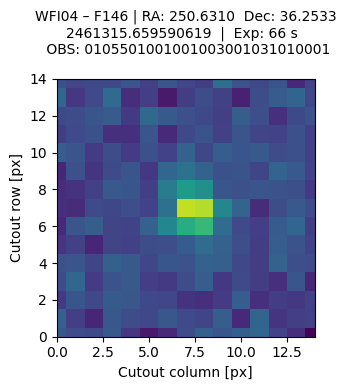

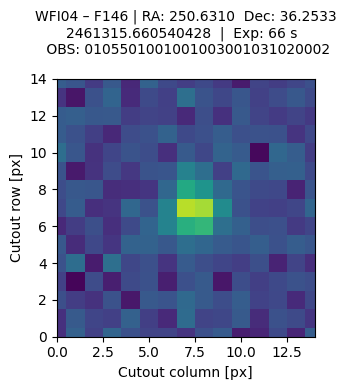

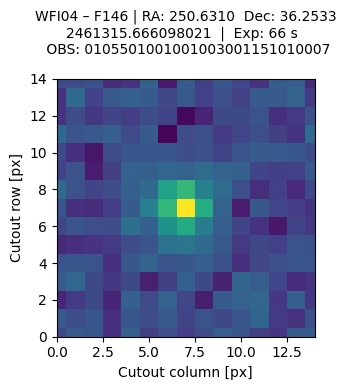

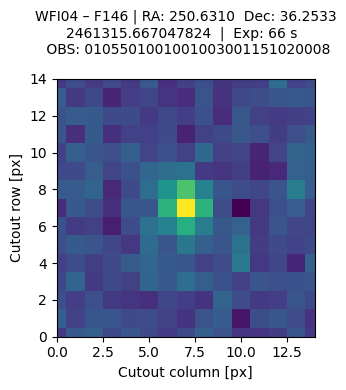

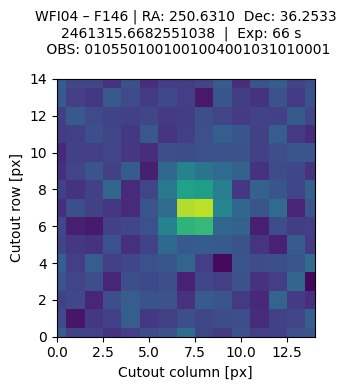

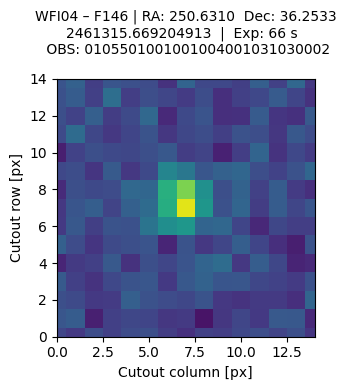

In [ ]:
ny, nx = cube.shape[1], cube.shape[2]
norm = simple_norm(cube.ravel(), stretch="asinh", percent=99.9)

for k in range(len(cube)):
    origin = meta.loc[k, "origin_original"]  # (col_min, row_min) from Cutout2D
    xmin, ymin = int(origin[0]), int(origin[1])

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_title(
        f'{meta.loc[k, "detector"]} – {meta.loc[k, "optical_element"]} | '
        f'RA: {meta.loc[k, "ra_target"]:.4f}  Dec: {meta.loc[k, "dec_target"]:.4f}\n'
        f'{meta.loc[k, "mid_time"]}  |  '
        f'Exp: {meta.loc[k, "exposure_time"]:.0f} s  \n '
        f'OBS: {meta.loc[k, "observation_id"]}\n',
        fontsize=10,
    )
    ax.pcolormesh(
        np.arange(nx),
        np.arange(ny),
        cube[k],
        norm=norm,
    )
    ax.set_aspect("equal", "box")
    ax.set_xlim(0, nx - 1)
    ax.set_ylim(0, ny - 1)
    ax.set_xlabel("Cutout column [px]")
    ax.set_ylabel("Cutout row [px]")
    plt.tight_layout()
    plt.show()


In [ ]:
# 4. Save cutouts to a single ASDF
OUT_PATH = "/home/jorgemarpa/teams/romcom/data/jmartinez/data/cutouts"
OUT_PATH = os.path.join(OUT_PATH, f"program_{pid}")
os.path.makedirs(OUT_PATH, exist_ok=True)

filename = os.path.join(OUT_PATH, f"cutouts_{pid}_{detector}_{filter}_{ra:.6f}_{dec:.6f}.asdf")

save_to_asdf(cube, meta, gwcss, filename)

AttributeError: module 'posixpath' has no attribute 'makedirs'